# Session 2 - Where the honest number comes from

**Solutions.** Worked code and the numbers you should expect.

## Where the honest number comes from

Session 1 ended with two numbers for the same model: 0.56 from cross-validation,
and anything between about 0.50 and 0.61 depending on which split you happened
to take. Today we quantify that variability, and then look at four ways of
accidentally inflating the number — only two of which actually bite on this
dataset. Measuring which ones bite, rather than assuming, is the point.

**This session (2 h)**

1. The split lottery: how much is a single test-set score worth?
2. Pipelines, and why they are not a stylistic preference
3. Leakage you can measure: preprocessing, feature selection, duplicate molecules
4. A checklist you can apply to someone else's paper

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so that `import qsar_helpers` works
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qsar_helpers import (load_fish, load_aquatic, xy, fold_error,
                          molecule_groups, score_table,
                          DESCRIPTOR_NOTES, TARGET_LABEL)

RNG = 0                            # one seed for the whole notebook
plt.rcParams.update({"figure.figsize": (6, 4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

pandas 3.0.6
scikit-learn 1.9.1


In [2]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (KFold, GroupKFold, RepeatedKFold,
                                     train_test_split, cross_val_score,
                                     cross_val_predict)
from sklearn.metrics import r2_score

fish = load_fish()
X, y = xy(fish)
cv5 = KFold(n_splits=5, shuffle=True, random_state=RNG)

## 1. The split lottery

### EXERCISE 2.1

Fit a random forest on a 75/25 split and score it on the held-out quarter.
Do this for 200 different values of `random_state` in the **split** (keep the
forest's own seed fixed, so that only the split changes). Plot the 200 scores as
a histogram and report mean, sd, min and max.

Then: find the seed that gives the highest score, and write down the sentence
you could put in an abstract if you only reported that one.

*Runtime is about a minute. Use `n_estimators=200`.*

mean 0.612  sd 0.045  min 0.461  max 0.725
5th-95th percentile: 0.541 - 0.679
best seed: 69


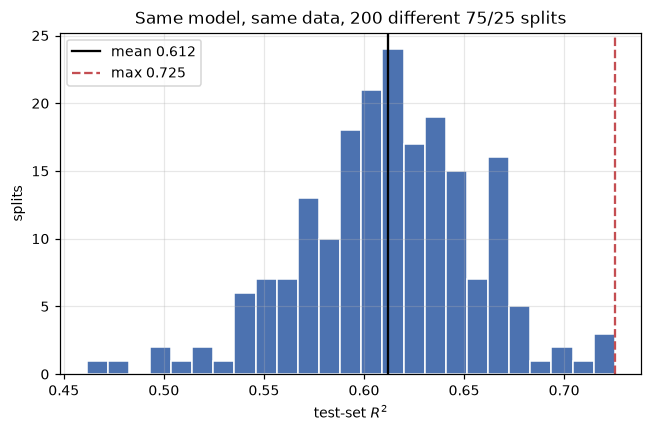

In [3]:
scores = []
for seed in range(200):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=seed)
    rf = RandomForestRegressor(n_estimators=200, random_state=RNG).fit(X_tr, y_tr)
    scores.append(r2_score(y_te, rf.predict(X_te)))
scores = np.array(scores)

fig, ax = plt.subplots()
ax.hist(scores, bins=25, color="#4C72B0", edgecolor="white")
ax.axvline(scores.mean(), color="k", lw=1.5, label=f"mean {scores.mean():.3f}")
ax.axvline(scores.max(), color="#C44E52", lw=1.5, ls="--", label=f"max {scores.max():.3f}")
ax.set_xlabel("test-set $R^2$"); ax.set_ylabel("splits")
ax.set_title("Same model, same data, 200 different 75/25 splits")
ax.legend(); fig.tight_layout()

print(f"mean {scores.mean():.3f}  sd {scores.std():.3f}  "
      f"min {scores.min():.3f}  max {scores.max():.3f}")
print(f"5th-95th percentile: {np.quantile(scores, 0.05):.3f} - {np.quantile(scores, 0.95):.3f}")
print(f"best seed: {scores.argmax()}")

# "A random forest on six molecular descriptors predicted acute fish toxicity
#  with R2 = 0.73 on a held-out test set." - true, reproducible, and worthless.

The honest centre is about 0.61, and the range runs from roughly 0.46 to 0.73.
Nobody needs to fabricate anything to publish the 0.73: they just need to try a
few splits and stop looking when the number is pleasing. This is the single most
common way that published performance figures end up irreproducible.

The fix is not a better seed. It is to report an estimator whose own variability
you have measured — which is what repeated cross-validation gives you.

### EXERCISE 2.2 — how many repeats are enough?

`RepeatedKFold(n_splits=5, n_repeats=r)` averages r independent 5-fold runs.
Compute the mean R<sup>2</sup> of the random forest for r = 1, 2, 3, 5, 10 and
plot it against r. At what point does the estimate stop moving by more than
0.01?

n_repeats= 1  R2 = 0.603 +- 0.027  (5 folds)
n_repeats= 2  R2 = 0.602 +- 0.040  (10 folds)
n_repeats= 3  R2 = 0.605 +- 0.045  (15 folds)
n_repeats= 5  R2 = 0.609 +- 0.051  (25 folds)
n_repeats=10  R2 = 0.613 +- 0.051  (50 folds)


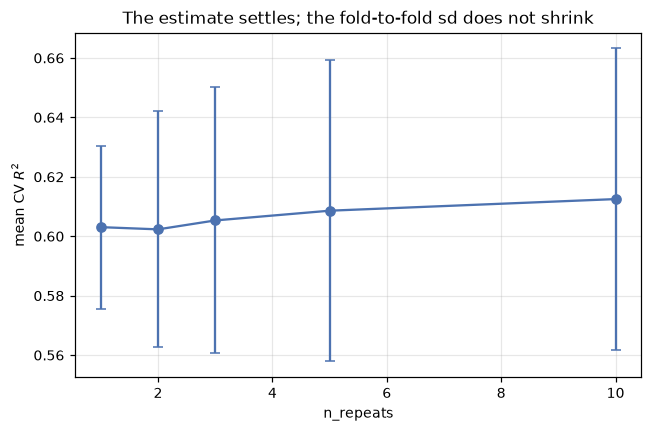

In [4]:
rows = []
for r in (1, 2, 3, 5, 10):
    cv = RepeatedKFold(n_splits=5, n_repeats=r, random_state=RNG)
    s = cross_val_score(RandomForestRegressor(n_estimators=200, random_state=RNG),
                        X, y, cv=cv, scoring="r2")
    rows.append((r, s.mean(), s.std()))
    print(f"n_repeats={r:>2d}  R2 = {s.mean():.3f} +- {s.std():.3f}  ({len(s)} folds)")

rows = np.array(rows)
fig, ax = plt.subplots()
ax.errorbar(rows[:, 0], rows[:, 1], yerr=rows[:, 2], marker="o", capsize=3, color="#4C72B0")
ax.set_xlabel("n_repeats"); ax.set_ylabel("mean CV $R^2$")
ax.set_title("The estimate settles; the fold-to-fold sd does not shrink")
fig.tight_layout()

# The mean is stable to within ~0.01 from about 3 repeats (0.603, 0.602,
# 0.605, 0.609, 0.613). The sd behaves differently: it *rises* from 0.027 at
# one repeat to about 0.05 and then settles. With only 5 folds the sd is
# itself estimated from 5 numbers and is badly underestimated; more repeats
# give a better estimate of a fold-to-fold variability that is a property of
# the data and does not shrink however long you compute.

Two distinct quantities get confused here. The **mean** is your performance
estimate, and more repeats make it more precise. The **sd across folds** is a
property of the data and model, and it does not shrink with more repeats — it is
what tells you whether a 0.02 difference between two models means anything.

## 2. Pipelines

A `Pipeline` bundles preprocessing with the model so that `fit` is only ever
called on training data. Before treating that as bureaucracy, check whether
scaling matters at all.

### EXERCISE 2.3

For k-nearest-neighbours (k=5), ridge regression (alpha=10) and a random forest,
compare 5-fold CV R<sup>2</sup> with and without `StandardScaler`. Explain the
pattern you see from how each algorithm works.

In [5]:
for name, est in [("kNN(k=5)", KNeighborsRegressor(n_neighbors=5)),
                  ("Ridge(10)", Ridge(alpha=10)),
                  ("RandomForest", RandomForestRegressor(n_estimators=200, random_state=RNG))]:
    raw = cross_val_score(est, X, y, cv=cv5, scoring="r2").mean()
    scaled = cross_val_score(make_pipeline(StandardScaler(), est), X, y, cv=cv5, scoring="r2").mean()
    print(f"{name:>13s}  unscaled {raw:.3f}   scaled {scaled:.3f}   diff {scaled-raw:+.3f}")

# kNN improves by ~0.045: it measures Euclidean distance, so MLOGP (sd 1.43)
# would otherwise dominate NdsCH (sd 0.61) purely through its units.
# Ridge is unchanged in R2 (the fit is equivariant up to the penalty, which is
# weak here). Trees split one feature at a time on thresholds, so any monotone
# rescaling leaves them identical.

     kNN(k=5)  unscaled 0.564   scaled 0.609   diff +0.045
    Ridge(10)  unscaled 0.556   scaled 0.557   diff +0.001
 RandomForest  unscaled 0.603   scaled 0.603   diff +0.000


So scaling is a modelling decision for distance-based methods and a no-op for
trees. The reason to put it in a `Pipeline` is different, and it is the subject
of the rest of the session.

## 3. Leakage, measured

"Leakage" means information from the evaluation data reaching the model. We will
look at three mechanisms, and **measure** each one on this dataset rather than
assuming it matters.

### 3a. Scaling fitted on everything

The natural-looking mistake: scale the whole matrix, then cross-validate. Each
fold's model has then seen the mean and sd of the test fold.

### EXERCISE 2.4

Measure the size of this effect for kNN on this dataset: scale `X` once up
front and cross-validate, versus scaling inside a pipeline. Report the gap.

In [6]:
X_pre = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
wrong = cross_val_score(KNeighborsRegressor(5), X_pre, y, cv=cv5, scoring="r2").mean()
right = cross_val_score(make_pipeline(StandardScaler(), KNeighborsRegressor(5)),
                        X, y, cv=cv5, scoring="r2").mean()
print(f"scaled before CV : {wrong:.4f}")
print(f"scaled inside CV : {right:.4f}")
print(f"optimism         : {wrong-right:+.4f}")

scaled before CV : 0.6131
scaled inside CV : 0.6093
optimism         : +0.0038


About +0.004 — nothing, and far below the ±0.05 fold-to-fold noise. A mean and a
standard deviation computed from 908 molecules barely change when you remove
180 of them.

This is worth dwelling on, because the lesson is not the one students usually
take away. The correct conclusion is **not** "scaler leakage is harmless, skip
the pipeline". It is:

- the *magnitude* of a leak depends on how much the leaked statistic depends on
  the individual rows — which is why the same mistake is catastrophic with 30
  samples and invisible with 900;
- you cannot know the magnitude without measuring, and you cannot measure it in
  someone else's paper;
- so the practice has to be defended by argument, not by effect size.

The next mechanism is the same mistake applied to a statistic that *does* depend
strongly on individual rows.

### 3b. Feature selection fitted on everything

Real QSAR descriptor sets have thousands of columns, not six, and are routinely
filtered down before modelling. To put ourselves in that regime, we will take a
small subset of molecules and give ourselves a large matrix of **pure noise**
descriptors — columns generated from a random number generator, which by
construction contain no information about toxicity whatsoever.

Any performance we obtain from these columns is, definitionally, an artefact.

### EXERCISE 2.5

With 60 molecules and 2000 noise descriptors:

1. Select the 10 noise columns most correlated with `y` using `SelectKBest` on
   the **whole** matrix, then cross-validate a ridge regression on those 10.
2. Do it properly: put `SelectKBest` and `Ridge` in a `Pipeline` and
   cross-validate that, so selection happens inside each fold.

Report both R<sup>2</sup> values. Remember that the honest answer is "no better
than the dummy".

In [7]:
rng = np.random.default_rng(RNG)
idx = rng.choice(len(X), 60, replace=False)
y_sub = y[idx]
noise = pd.DataFrame(rng.normal(size=(60, 2000)),
                     columns=[f"noise_{i:04d}" for i in range(2000)])
print(noise.shape, "pure noise descriptors for", len(y_sub), "molecules")

from sklearn.feature_selection import SelectKBest, f_regression
cv_sub = KFold(5, shuffle=True, random_state=RNG)

# (1) the mistake: choose the columns using every molecule, then "validate"
sel = SelectKBest(f_regression, k=10).fit(noise, y_sub)
chosen = noise.loc[:, sel.get_support()]
wrong = cross_val_score(make_pipeline(StandardScaler(), Ridge(1.0)),
                        chosen, y_sub, cv=cv_sub, scoring="r2").mean()

# (2) selection is part of the model, so it belongs inside the fold
pipe = Pipeline([("select", SelectKBest(f_regression, k=10)),
                 ("scale", StandardScaler()),
                 ("model", Ridge(1.0))])
right = cross_val_score(pipe, noise, y_sub, cv=cv_sub, scoring="r2").mean()

print(f"select on all data, then CV : R2 = {wrong:+.3f}")
print(f"select inside each fold     : R2 = {right:+.3f}")

(60, 2000) pure noise descriptors for 60 molecules
select on all data, then CV : R2 = +0.386
select inside each fold     : R2 = -0.177


Selecting first gives R<sup>2</sup> ≈ **+0.39 from random numbers**. Done
correctly the same procedure scores about **-0.18**, i.e. worse than predicting
the mean, which is the truth.

The mechanism: with 2000 candidates and 60 molecules, some columns correlate
with `y` by chance alone, and the strongest of them do so *on these particular
60 molecules*. Choosing them using all 60 molecules, including the ones you then
treat as held out, hands the model a fingerprint of the test rows. Nothing about
the subsequent cross-validation can undo that — the fold split happens after the
information has already moved.

This is not a toy failure mode. It is the standard explanation for biomarker
panels that do not replicate: gene filtering, probe selection, or
differential-expression screening done once on the full cohort, followed by
cross-validation of the classifier only.

### EXERCISE 2.6 — vary the regime

Repeat 2.5 for a few combinations of sample size and descriptor count:
(n=60, p=500), (n=60, p=2000), (n=120, p=2000), (n=300, p=2000). The artefact
is itself a random quantity, so **average five independent draws** of molecules
and noise per combination and report the mean. How does the size of the artefact
depend on n, and on p?

In [8]:
from sklearn.feature_selection import SelectKBest, f_regression

def noise_experiment(n_sub, p, seed):
    rg = np.random.default_rng(seed)
    ii = rg.choice(len(X), n_sub, replace=False)
    ys = y[ii]
    nz = pd.DataFrame(rg.normal(size=(n_sub, p)), columns=[f"n{i}" for i in range(p)])
    cvk = KFold(5, shuffle=True, random_state=RNG)
    s = SelectKBest(f_regression, k=10).fit(nz, ys)
    w = cross_val_score(make_pipeline(StandardScaler(), Ridge(1.0)),
                        nz.loc[:, s.get_support()], ys, cv=cvk, scoring="r2").mean()
    r = cross_val_score(Pipeline([("s", SelectKBest(f_regression, k=10)),
                                  ("sc", StandardScaler()), ("m", Ridge(1.0))]),
                        nz, ys, cv=cvk, scoring="r2").mean()
    return w, r

rows = []
for n_sub, p in [(60, 500), (60, 2000), (120, 2000), (300, 2000)]:
    res = np.array([noise_experiment(n_sub, p, seed) for seed in range(5)])
    rows.append(dict(n=n_sub, p=p,
                     select_then_CV=round(res[:, 0].mean(), 3),
                     sd=round(res[:, 0].std(), 3),
                     select_inside_CV=round(res[:, 1].mean(), 3)))
print(pd.DataFrame(rows).to_string(index=False))

# The artefact grows with p (more candidate columns, so a stronger best-of-p
# chance correlation) and shrinks with n (a chance correlation over more
# molecules is less specific to the rows you are about to score). Note the sd
# across draws: a single draw is not enough to order these regimes, which is
# the same lesson as exercise 2.1 applied to the artefact itself.

  n    p  select_then_CV    sd  select_inside_CV
 60  500           0.234 0.186            -0.595
 60 2000           0.421 0.127            -0.511
120 2000           0.251 0.089            -0.541
300 2000           0.151 0.047            -0.342


### 3c. The same molecule on both sides of the split

A mechanism specific to biological and chemical data: **rows that are not
independent**. Here, different entries can carry identical descriptor values —
either genuine duplicates, or distinct molecules that these six descriptors
cannot tell apart. If one lands in training and its twin in test, the model is
being asked a question it has already been given the answer to.

### EXERCISE 2.7

1. Use `molecule_groups(X)` to label rows with identical descriptor vectors.
   How many rows have at least one twin?
2. Compare 5-fold `KFold` with 5-fold `GroupKFold` (passing those labels as
   `groups=`) for kNN with k=1, k=5 and a random forest. How large is the gap?
3. The aggregate gap will surprise you. Use `cross_val_predict` with k=1 under
   both schemes and compute R<sup>2</sup> **separately** on the twinned rows and
   on the rows with no twin. Now how large is it?

In [9]:
groups = molecule_groups(X)
has_twin = pd.Series(groups).duplicated(keep=False).to_numpy()
print(f"{len(X)} rows, {len(set(groups))} distinct descriptor vectors, "
      f"{has_twin.sum()} rows with at least one twin")

print("\n(2) aggregate comparison")
for name, est in [("kNN(k=1)", make_pipeline(StandardScaler(), KNeighborsRegressor(1))),
                  ("kNN(k=5)", make_pipeline(StandardScaler(), KNeighborsRegressor(5))),
                  ("RandomForest", RandomForestRegressor(n_estimators=200, random_state=RNG))]:
    a = cross_val_score(est, X, y, cv=cv5, scoring="r2").mean()
    b = cross_val_score(est, X, y, cv=GroupKFold(5), groups=groups, scoring="r2").mean()
    print(f"  {name:>13s}  random {a:.3f}   grouped {b:.3f}   gap {a-b:+.3f}")

print("\n(3) k=1, scored separately on the affected and unaffected rows")
k1 = make_pipeline(StandardScaler(), KNeighborsRegressor(1))
p_rand = cross_val_predict(k1, X, y, cv=cv5)
p_grp = cross_val_predict(k1, X, y, cv=GroupKFold(5), groups=groups)
for label, mask in [("rows with a twin", has_twin), ("rows without", ~has_twin)]:
    print(f"  {label:>17s} (n={mask.sum():3d}):  random {r2_score(y[mask], p_rand[mask]):.3f}"
          f"   grouped {r2_score(y[mask], p_grp[mask]):.3f}")

908 rows, 775 distinct descriptor vectors, 217 rows with at least one twin

(2) aggregate comparison
       kNN(k=1)  random 0.406   grouped 0.415   gap -0.009
       kNN(k=5)  random 0.609   grouped 0.606   gap +0.004
   RandomForest  random 0.603   grouped 0.605   gap -0.002

(3) k=1, scored separately on the affected and unaffected rows
   rows with a twin (n=217):  random 0.649   grouped 0.519
       rows without (n=691):  random 0.375   grouped 0.397


The aggregate gap is about +0.004 for k=1 — apparently nothing. But restricted to
the 217 rows that actually have a twin, k=1 scores **0.65 with a random split and
0.52 with a grouped split**. On the 691 rows with no twin there is no gap at all.

Both facts are true and they teach different things:

- the leak is real, large, and exactly where the mechanism predicts it;
- averaged over a dataset where 76% of rows are unaffected, and with a model that
  does not rely purely on memorising single neighbours, it vanishes into the
  noise.

So "we checked and it made no difference to the headline number" is not evidence
that a dependence structure is harmless. It may only mean the affected fraction
is small. When your replicates *are* the majority of your data — multiple cell
lines per patient, several images per animal, homologous sequences across a
protein family, repeat measurements of the same compound — the aggregate effect
is the 0.13, not the 0.004.

And note which direction the honest choice goes: `GroupKFold` here gives a
*lower* score. Correct methodology generally costs you performance on paper.

## Session 2 checklist

Things you can now check in any supervised-learning paper or thesis chapter.

1. Is a baseline reported? Dummy, or a single-descriptor model?
2. Is the headline score a single split, or an average with a spread?
3. Is every data-dependent step — scaling, imputation, feature selection,
   dimensionality reduction, outlier removal — inside the resampling loop?
4. Are the rows independent? If not, is the split grouped accordingly?
5. Would the authors have reported a different number if the first split had
   been unlucky? Can you tell?

### EXERCISE 2.8 — homework, 20 minutes

Take the leakage mechanism from 3b and write out, in five sentences, how the
equivalent mistake would look in a study you might actually run: 40 patient
samples, 20000 transcripts, a two-group outcome, and a feature-filtering step.
State precisely where in the pipeline the test-set information enters.